# Quantum Metal A.1 — transmon with readout resonator (Quantcore PDK rebuild)

**What the chip is.** The canonical superconducting-qubit unit cell from the Qiskit Metal tutorial
`docs/tut/full-design-examples/A.1-Transmon-with-readout-resonator.ipynb` (© IBM / Qiskit Metal contributors,
Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; the tutorial itself adapts the SQDMetal benchmark
devices of Sommers *et al.*, arXiv:2511.01220): one fixed-frequency `TransmonPocket` (pad width 425 µm, pocket
height 650 µm, a `readout` connection pad at its upper right), a 7 mm meandered λ/4 readout resonator, and a
`CoupledLineTee` on a feedline between two `LaunchpadWirebond`s. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options, but the chip, the
stack, the junction, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 9 × 6 mm centred on (0, 0) | the same 9 × 6 mm box (it does not fit the 7.5 mm die), shifted by (+4.5, +3) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | `LaunchpadWirebond` at x = ±4 mm (outer edge 240 µm in) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junction | Metal junction line, `hfss_inductance` 10 nH | Quantcore Nb/AlOx/Nb trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | none (the tutorial never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RoutePathfinder` feedline halves, `RouteMeander` 7 mm | qcc `cpw` routes on the same pins; a 7 mm qcc meander (turn radius 90 µm = Metal's fillet) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options (`pad_width`, `pocket_height`, `connection_pads`,
`coupling_length` 350 µm, `down_length` 300 µm, `fillet` 90 µm, `open_termination=False`, the launchpad
orientations), their relative positions, every route's end pins and the readout's total length.

**Simplified:** the qcc router puts the meander on the longest straight between the tee and the qubit (Metal's
`RouteMeander` uses its own 100 µm lead straights and meander spacing), so the readout's shape differs, not its
length.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the two bond pads, the readout line (the tee on its feedline), the qubit, the
readout resonator, and then the whole chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `a1_transmon_readout.v1.ipynb`; both save the same
`a1_transmon_readout.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 9 × 6 mm box gets the QCT frame; the two launchpads go 100 µm from the west and east edges; Q1 gets the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so the feedline (pad → tee → pad) is drawn as soon as the
pads and the tee exist (segment 3), and the readout resonator once the qubit is there (segment 5).

| segment | what is placed here |
|---|---|
| 1 | the 9 × 6 mm die with the QCT frame |
| 2 | the two feedline launchpads, 100 µm from the west / east edges |
| 3 | the readout line: the coupled-line tee on its feedline (two `cpw` halves) |
| 4 | the qubit with its trilayer junction |
| 5 | the 7 mm λ/4 readout resonator from the tee to the qubit |
| 6–7 | nothing: one qubit, no bus, no control line |
| 8 | the whole chip: sim group, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (it is optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position is shifted by `(X0, Y0)` = half the chip.

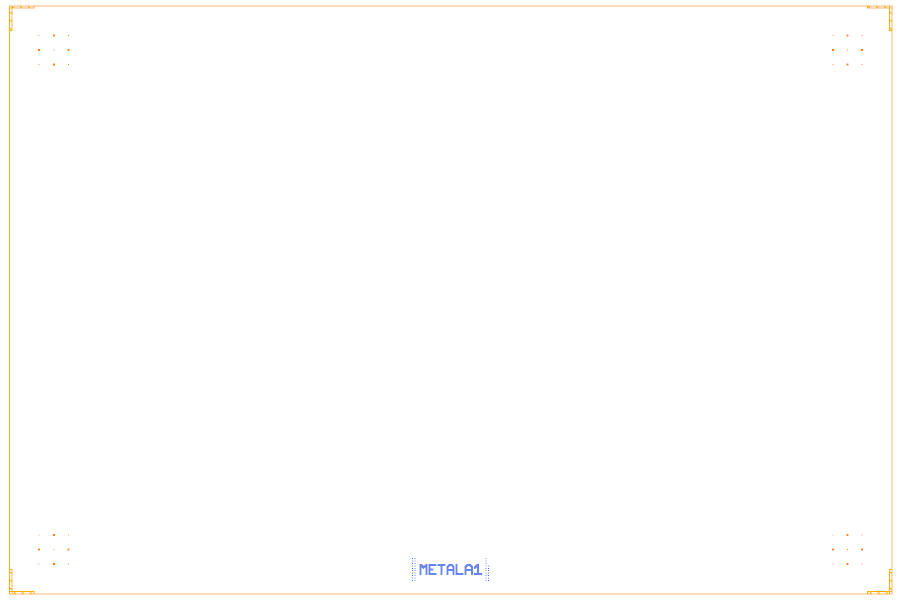

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a1_transmon_readout_s1_die.png')

In [5]:
d = Designer("a1_transmon_readout", box=(0, 0, 9000, 6000), chip={"name_chip": "MetalA1"}, live=LIVE)
X0, Y0 = 4500, 3000                              # Metal's 9 × 6 mm chip is centred on (0, 0)
layout_step(d, OUT / "a1_transmon_readout_s1_die.png", size=(900, 600), width=450)

## Design 2 · Bond pads: the PDK pad rule

The tutorial puts its two `LaunchpadWirebond`s at x = ±4 mm on the feedline height. In the Quantcore PDK the outer
edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**, whatever the source did:
`edge="w"` / `"e"` (or `"auto"`, the nearest edge) slides the pad perpendicular to that edge until it is there; its
position along the edge (the feedline height) is kept. The table measures it on the built layout; the picture zooms on the west pad `LP1`.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP1 | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP2 | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

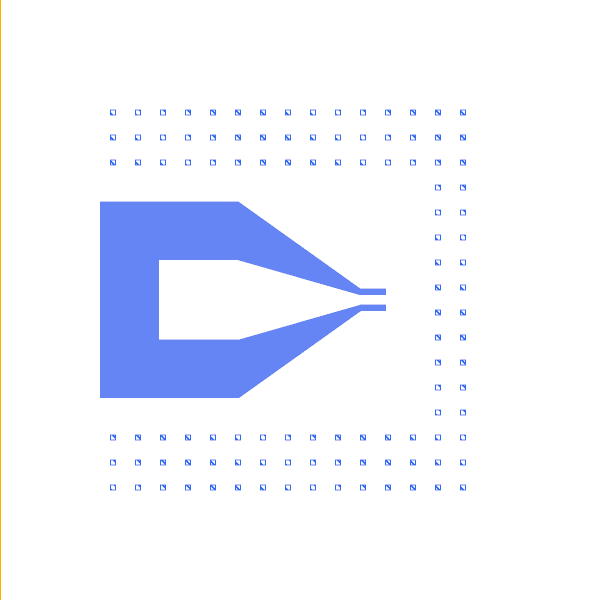

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `LP1`, `LP2`.

WindowsPath('examples/designs/metal/a1_transmon_readout_s2_pads.png')

In [6]:
with d.batch():
    lp1 = d.add("LP1", "metal:LaunchpadWirebond", at=(X0 - 4000, Y0 + 1500), rot=0, edge="w")
    lp2 = d.add("LP2", "metal:LaunchpadWirebond", at=(X0 + 4000, Y0 + 1500), rot=180, edge="e")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "LP1.tie")
layout_step(d, OUT / "a1_transmon_readout_s2_pads.png", box=(0, py - 300, 600, py + 300), size=(600, 600), width=300)

## Design 3 · Readout: the tee on its feedline

The readout line needs no qubit, so it comes first. `metal:CoupledLineTee` is a feedline section with a 350 µm coupled arm; `open_termination=False` shorts
the arm's far end, so the resonator routed from `second_end` is a λ/4 shorted at the tee. The tee sits 1.5 mm above the
chip centre, at the launchpads' height.

**Feedline:** two `cpw` routes, launchpad → tee → launchpad (`feed_L`, `feed_R`), on the PDK's default CPW (10 µm
centre, 6 µm gap) with the tutorial's 90 µm fillet as the turn radius. The tee's `second_end` stays open until the
resonator arrives in segment 5.

clt ports: ['prime_end', 'prime_start', 'second_end']


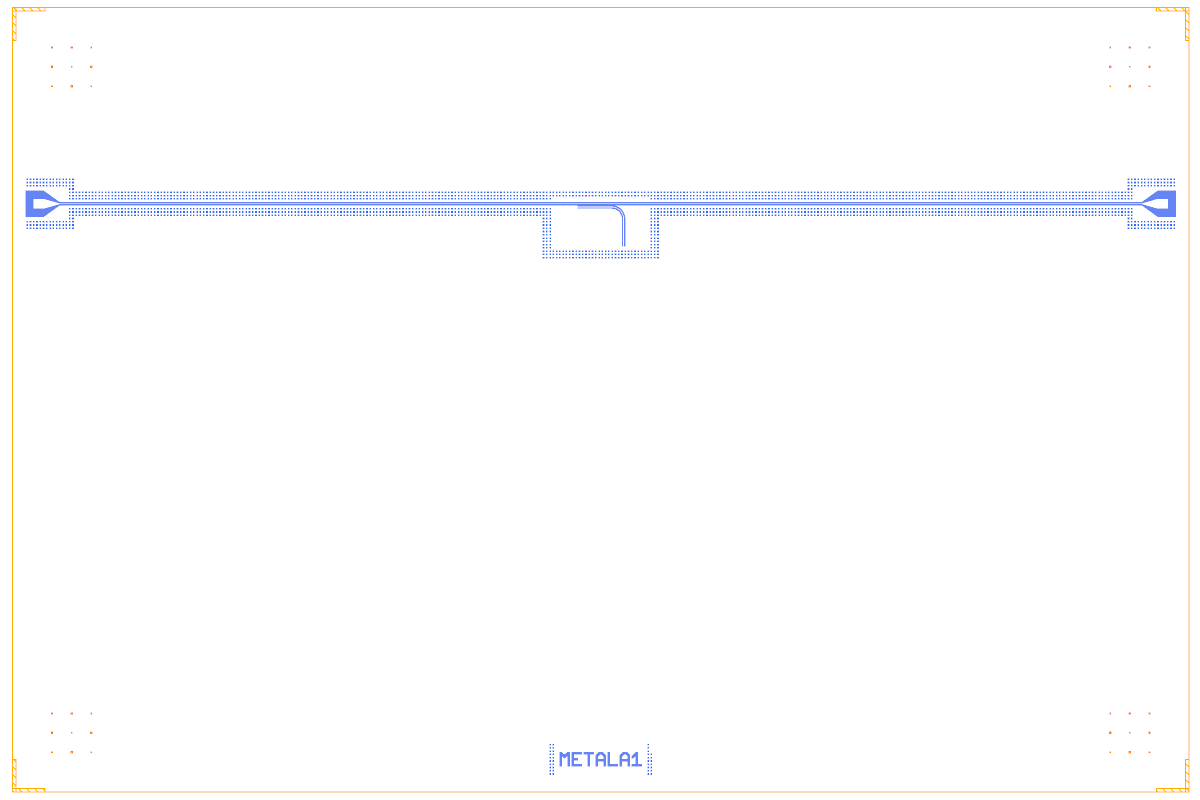

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** 1 component(s) `clt` and 2 route(s) `feed_L`, `feed_R`.

WindowsPath('examples/designs/metal/a1_transmon_readout_s3_readout_line.png')

In [7]:
with d.batch():
    clt = d.add("clt", "metal:CoupledLineTee", at=(X0 + 0, Y0 + 1500), coupling_length=350, down_length=300,
                fillet=90, open_termination=False)
    d.route("feed_L", lp1.tie, clt.prime_start, r=90)
    d.route("feed_R", clt.prime_end, lp2.tie, r=90)
print("clt ports:", sorted(clt.ports))
layout_step(d, OUT / "a1_transmon_readout_s3_readout_line.png", size=(1200, 800), width=480)

## Design 4 · Qubit placement: the pocket transmon

**The qubit.** `metal:TransmonPocket` is Metal's pocket transmon drawn by the wrapper with the tutorial's options:
two 425 µm pads in a 650 µm-high pocket and one connection pad `readout`. Its junction is the PDK's: with
`junction_type` unset the wrapper already draws the Quantcore trilayer junction; `trilayer_junction` makes it
explicit and returns the drawn junction's L_J and C_J, which the LOM and the FEM junction port use (`junction=`).
The tutorial gives no target frequency, so Q1 gets the PDK nominal junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a
50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF).

Each component has named **ports** (Metal's pins): routes connect to them, and the LOM maps each to a circuit node.
The qubit hangs 1.5 mm below the chip centre, 3 mm below its tee. The first picture is the chip so far; the second
zooms on the qubit and the tee above it.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['readout', 'squid_a', 'squid_b']


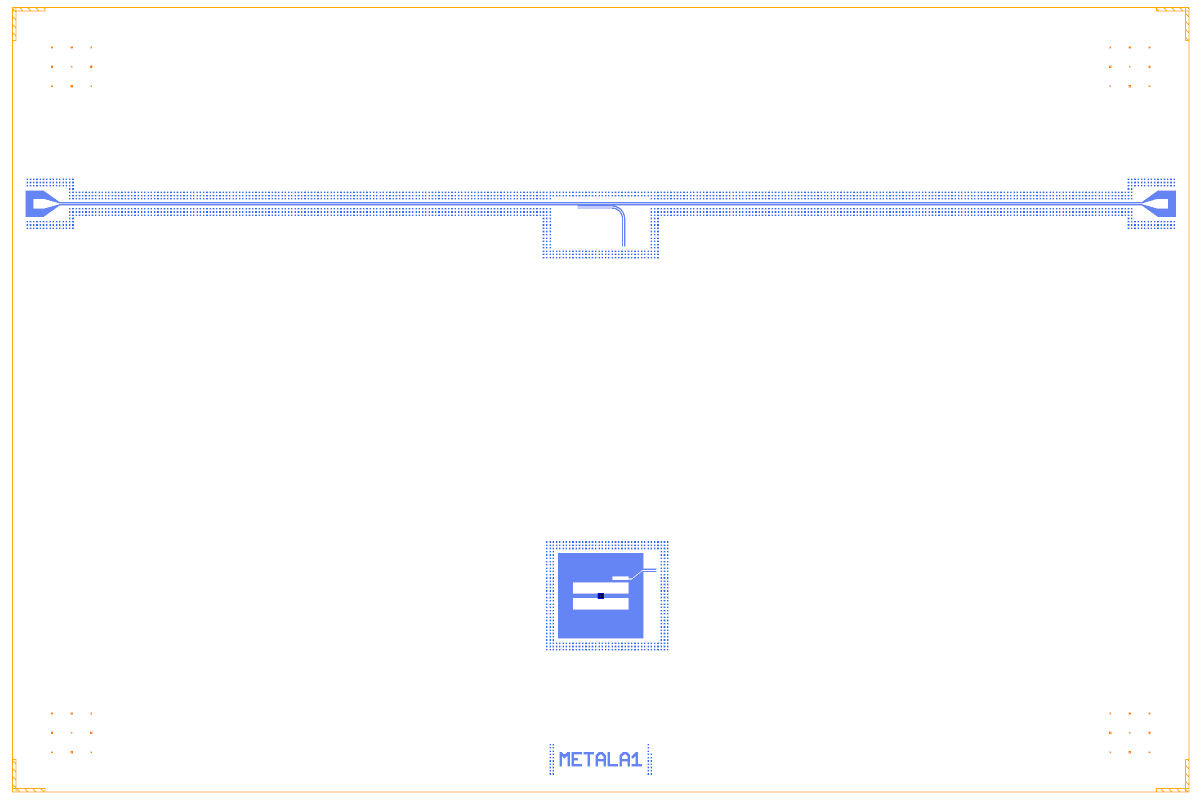

**On the chip so far:** 2 pads · 1 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** 1 component(s) `Q1`.

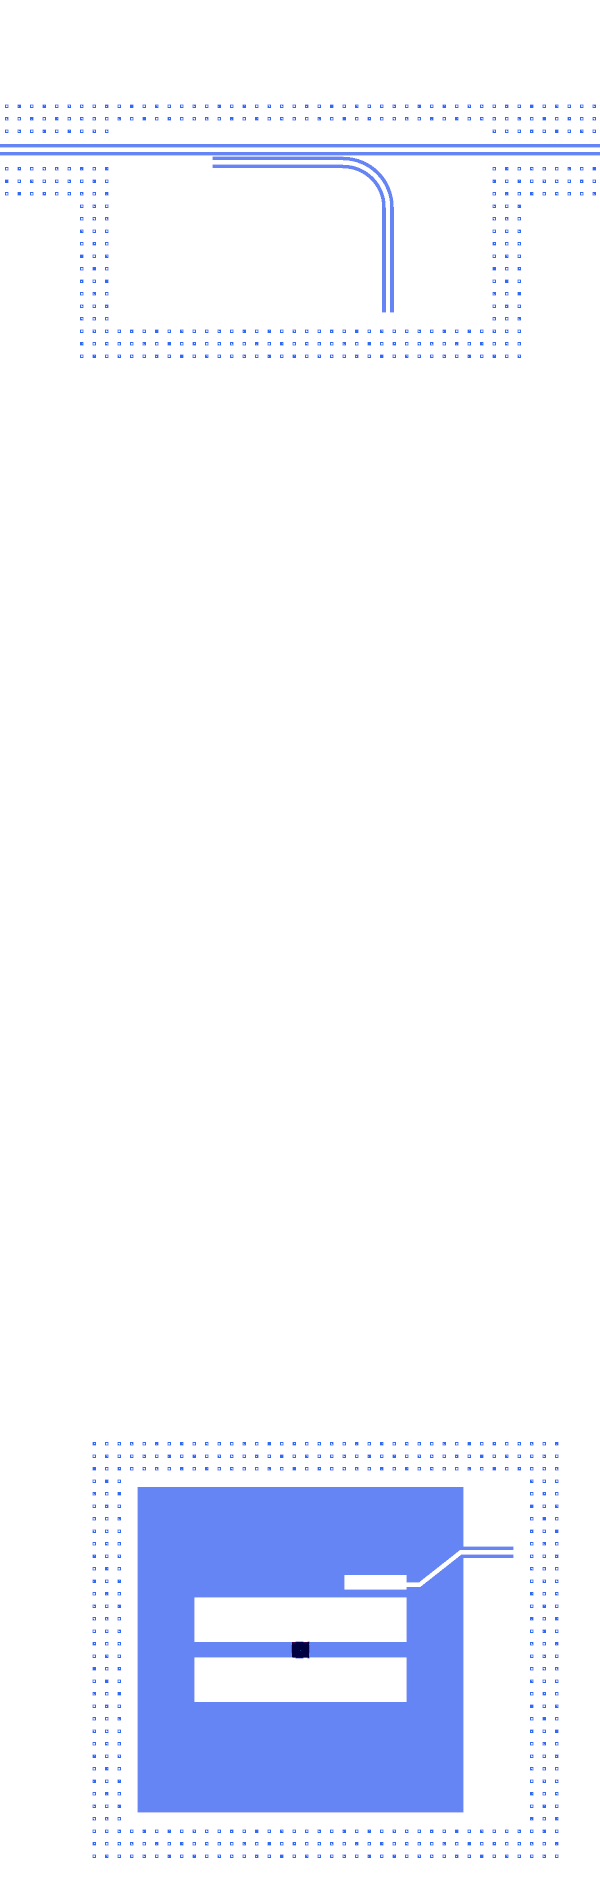

WindowsPath('examples/designs/metal/a1_transmon_readout_step_parts.png')

In [8]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    q1 = d.add("Q1", "metal:TransmonPocket", at=(X0 + 0, Y0 - 1500), pad_width=425, pocket_height=650,
               connection_pads={"readout": {"loc_W": 1, "loc_H": 1}}, junction=JUNCTION, **JJ_PARAMS)
print("Q1 ports:", sorted(q1.ports))
layout_step(d, OUT / "a1_transmon_readout_s4_qubit.png", size=(1200, 800), width=480)
snap(d, OUT / "a1_transmon_readout_step_parts.png", box=(X0 - 600, Y0 - 2000, X0 + 600, Y0 + 1800), size=(600, 1900),
     width=240)

## Design 5 · Readout: the λ/4 readout resonator

`meander=7000` makes a fixed-length route from the tee's coupled arm (`clt.second_end`) to the qubit's readout pad;
the length sets the frequency (λ/4 on sapphire: f ≈ v_ph / 4ℓ). With no waypoints the router draws the shortest path
between the two pins and puts the length the path leaves over into one KQC `Meander` on its longest free straight
(turn radius 90 µm, Metal's fillet). Metal's `RouteMeander` uses its own 100 µm lead straights and meander spacing,
so the readout's shape differs from the tutorial's, not its length.

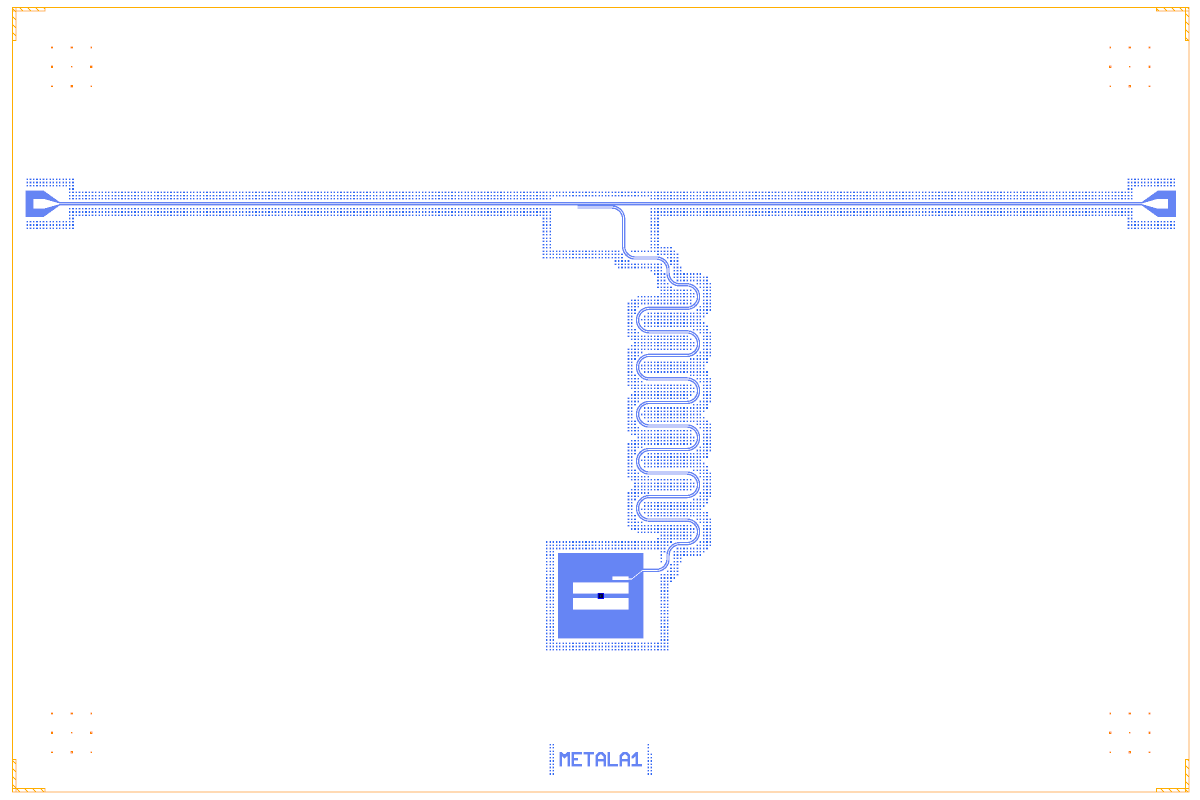

**On the chip so far:** 2 pads · 1 qubits · 1 other components · 3 routes · 0 declared couplings. **This step added** 1 route(s) `readout_res`.

WindowsPath('examples/designs/metal/a1_transmon_readout_s5_readout.png')

In [9]:
with d.batch():
    d.route("readout_res", clt.second_end, q1.readout, meander=7000, r=90)
layout_step(d, OUT / "a1_transmon_readout_s5_readout.png", size=(1200, 800), width=480)

## Design 6 · Coupling

One qubit, so nothing to couple: the only coupling on this chip is the qubit's readout pad to its resonator
(segment 5).

## Design 7 · Routing: control lines

The tutorial draws no charge or flux line: the qubit is driven and read through its readout. Nothing is placed here.

## Design 8 · The whole chip: sim group, centring, save

**Sim group.** `sim_group` names the part of the chip a FEM job cuts out — the qubit, its readout and the tee
(`Q1_readout`) — and the analyses it gets (Q3D C-matrix and eigenmode).

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). Here the pads already span the die in x, so only y moves (the source's qubit hangs
below its feedline).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the tee was added before the qubit here), so `git diff` stays empty.

content shifted by (0.0, 113.5) µm


**Same design as before:** `examples/designs/metal/a1_transmon_readout.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer a1_transmon_readout: 4 instances, 3 routes, live=False> → examples\designs\metal\a1_transmon_readout.json
route lengths (µm): {'feed_L': 3765.0, 'feed_R': 3765.0, 'readout_res': 7000.0}


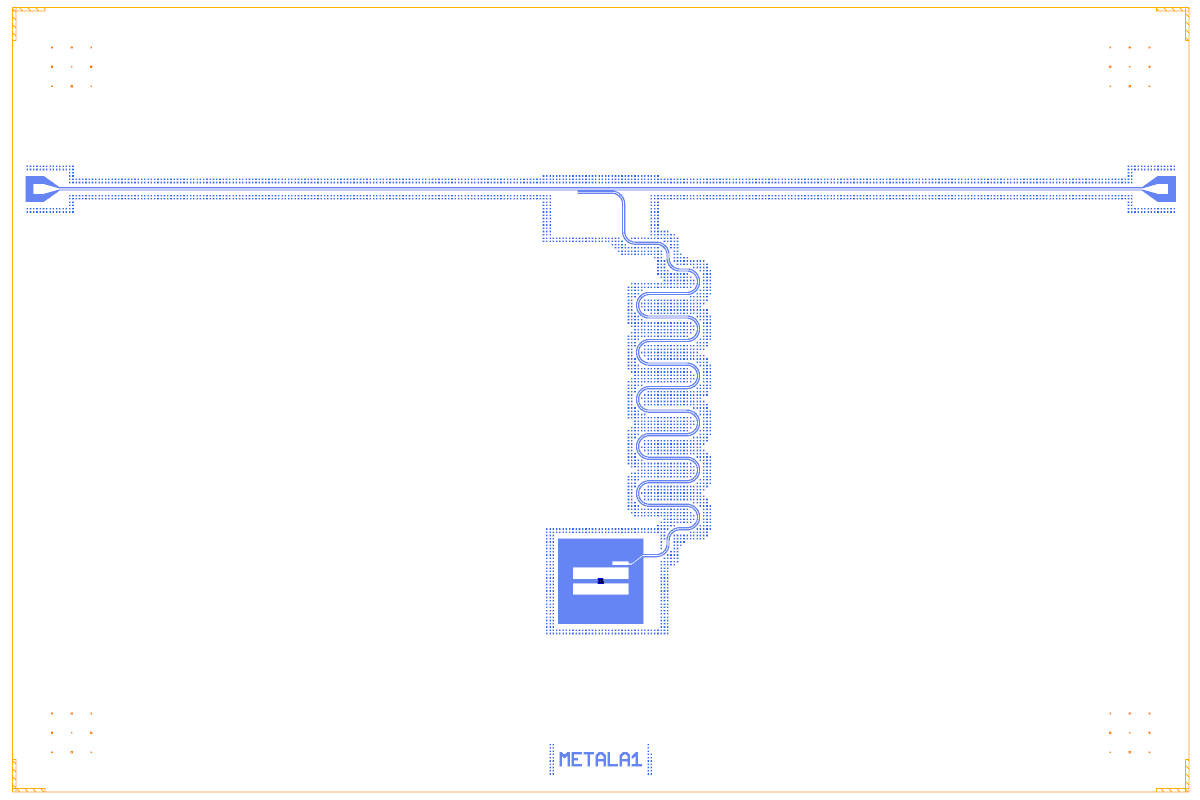

**On the chip so far:** 2 pads · 1 qubits · 1 other components · 3 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a1_transmon_readout_step_routes.png')

In [10]:
d.sim_group("Q1_readout", ["Q1", "readout_res", "clt"], analyses=["q3d_cmatrix", "eigenmode_epr"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "a1_transmon_readout.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "a1_transmon_readout_step_routes.png", size=(1200, 800), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**, two `dangling_port` warnings (`Q1.squid_a` / `squid_b`, the junction's
attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings** (the pads are at 100 µm, the nominal junction is in the R_n window, no target is outside 4–8 GHz).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model gives its nodes and branches (the
pocket transmon: an island with its junction and C_Σ, a node for the readout pad; the tee: a coupling capacitor and
a hanger κ), and each route joins the nodes of the ports at its ends (the readout route becomes a λ/4 `TLres`, the
feedline halves join the launchpad ports, 50 Ω each). The port map shows which node each port landed on. In the circuit the readout λ/4 is the tee's line `clt` (the
coupled arm and `readout_res` together, 7650 µm in the v1 run's netlist), so its values below are `clt.f_GHz`,
`clt.chi_MHz`, `clt.kappa_MHz`.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "clt."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat solves the circuit's normal modes (frequency, κ through the 50 Ω ports, anharmonicity); QuTiP diagonalises the
dressed Hamiltonian for f_q, α, f_r and χ. With the PDK junction (6.73 nH, 15 fF; numbers from the v1 run) the qubit sits near 7.4 GHz, above
the ≈ 4 GHz λ/4 readout as in the tutorial; the tutorial states no targets, so there is nothing to compare with
except the PDK band (4–8 GHz).

In [ ]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))

## LOM 2 · The LOM in two plots

The same result as pictures: (a) every normal mode of the circuit (QuCat; the circle is the qubit, the square the
readout; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of the readout. Here (from the v1
run) the qubit sits ≈ 3.5 GHz above its readout (7.44 against 3.93 GHz), so |χ| is small (≈ 0.2 MHz).

In [ ]:
plot_lom({"Q1 + readout": res}, OUT / "a1_transmon_readout_lom.png", title="a1: LOM of the chip")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here the readout meander, 7000 → 6500 µm — rebuild, re-run the LOM and compare. A
shorter λ/4 resonates higher (f ∝ 1/ℓ, about +7 %); χ follows the smaller qubit–resonator detuning.

In [ ]:
d2 = design_copy(DESIGN)
d2["readout_res"].set(length=6500)               # 7000 → 6500 µm
res2 = simulate_lom(d2.lom(), d2.design)
display(Markdown(params_delta_md(res, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Two jobs for the group `Q1_readout`: a **Q3D C-matrix** (the capacitances of the island pads, the readout
pad and the tee arm: they replace the LOM estimates) and an **eigenmode / EPR** job (the lines leaving the box end in
50 Ω, so the mode Q gives κ, and EPR gives the junction participation).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["Q1_readout"])
jobs_eig = export_sims(DESIGN, ["Q1_readout"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the component group `Q1_readout`: the qubit's two pads, its readout pad, the tee arm and the
feedline the box cuts, as named nets. Each net is named after its LOM node, so the matrix goes straight into the
circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there
are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same `Q1_readout` box in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet, and the feedline ends the box
cuts (`feed_L`, `feed_R`) end in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes), the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it.

The readout is a hanger on the feedline, so S21 between the two feedline ports shows its notch: the fit gives f_r
and the external κ.

In [ ]:
f_r = res.params.get("clt.f_GHz")                # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1_readout", jobs_eig["Q1_readout"][0], keep_eig["Q1_readout"], f_guess=f_r)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1_readout"]:
    display(Markdown(driven_md(keep_drv["Q1_readout"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q1": res.params.get("Q1.f_q_GHz"), "clt": f_r}
plot_eigenmodes(keep_eig, OUT / "a1_transmon_readout_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: the qubit's mode is the one its junction participates in most, the readout's
the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms,
κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch.

In [ ]:
fem_values = {}
if keep_eig["Q1_readout"]:
    fem_values = epr_values(keep_eig["Q1_readout"], {"Q1": "clt"}, {"clt": f_r})
if keep_drv["Q1_readout"]:
    fem_values.update({f"driven {k}": v for k, v in driven_values(keep_drv["Q1_readout"], "clt", f_r).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for k, v in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α of Q1 and f_r, χ, κ of its "
          "readout from pyEPR, and the S21 notch of the driven run.")

## Results 3 · FEM against the LOM

Two comparisons. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated components
by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM runs again.
**FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component estimates
(LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

keys = ["Q1.f_q_GHz", "Q1.alpha_MHz", "clt.f_GHz", "clt.chi_MHz", "clt.kappa_MHz"]
rows = []
if keep_q3d["Q1_readout"]:
    on_fem = simulate(fill(lb.model, DESIGN, keep_q3d["Q1_readout"]), max_modes=2).params
    rows += [(k, res.params.get(k), on_fem.get(k), "LOM on the Q3D C-matrix") for k in keys]
rows += [(k, res.params.get(k), fem_values[k], "eigenmode + pyEPR") for k in keys if k in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no targets, so this notebook sets one as an exercise: **Q1 at 7.2 GHz**, ≈ 0.25 GHz below where
the LOM puts it (from the v1 run: 7.445 GHz). It is reachable inside the PDK junction window: by the transmon formula
L_J goes from 6.73 nH to ≈ 7.2 nH, R_n ≈ 48 kΩ (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ). The readout is
not targeted (the tutorial gives no readout frequency); an f_r target would move the `readout_res` meander length.

The targets go on a copy (`target_copy` → `build/a1_transmon_readout_target.json`), so the design file keeps its own
(none). `loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on the qubit–readout pair of the
circuit — on the Q3D values when a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; to draw the new junction, size its fingers with `trilayer_junction(..., lj_nH=...)`.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 7.2}}               # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/a1_transmon_readout/revisions/`).
Without `RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's Q3D component job is
exported and solved first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table
shows each iteration's value against the target and the knob it moved; the plot the residual in tolerances (on
target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = export_sims(rev, ["Q1_readout"], root=f"build/jobs/rev{k}")
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "a1_transmon_readout_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The A.1 tutorial never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip; the qubit pocket; its trilayer junction; the readout pad where the meander lands; the coupled-line
tee; the **fab mask** round the qubit (1/0 etch with the PDK cheese band, the 3/0 keep-out, the junction layers);
and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are read from the
design (after the centring shift).

In [ ]:
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
TX, TY = d.data["instances"]["clt"]["place"]["at"]
show_snapshot(d, OUT / "a1_transmon_readout.png", size=(1800, 1200))
show_snapshot(d, OUT / "a1_transmon_readout_q1.png", box=(QX - 450, QY - 400, QX + 450, QY + 400), size=(1350, 1200),
              width=420)
show_snapshot(d, OUT / "a1_transmon_readout_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
rx, ry = port_xy(d, "Q1.readout")
show_snapshot(d, OUT / "a1_transmon_readout_pin.png", box=(rx - 60, ry - 60, rx + 60, ry + 60), width=300)
show_snapshot(d, OUT / "a1_transmon_readout_tee.png", box=(TX - 300, TY - 400, TX + 300, TY + 200), width=360)
snap_file(Path("build") / "a1_transmon_readout_fab.oas", OUT / "a1_transmon_readout_cheese.png",
          box=(QX - 450, QY - 400, QX + 450, QY + 400), size=(1350, 1200), width=420)
show_snapshot(d, OUT / "a1_transmon_readout_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins, the 7 mm readout, the sim group |
| PDK changes | QCT frame on the source's 9 × 6 mm box; sapphire stack; launchpads 100 µm from the west / east edges (were 240 µm); trilayer junction (PDK nominal); PDK cheese band; content centred (shift printed in Design 8) |
| differs | the readout meander's shape (qcc router); f_q ≈ 7.4 GHz with the PDK junction (from the v1 run; the 10 nH Metal default gave 6.75 GHz) |
| PDK design warnings | none |
| layout | built in segments (die, pads, the tee on its feedline, the qubit, the readout resonator, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q1 7.2 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |